In [71]:
from pathlib import Path
import pandas as pd

file_path = Path("/Users/wangshihan/Air Quality Research/2024_AIR_QUALITY.xlsx")
xls = pd.ExcelFile(file_path)
xls.sheet_names

['Data Info Panel',
 'Metadata',
 'AllData',
 'Morwell East_10017',
 'Mooroolbark_10136',
 'Altona North_10006',
 'Dandenong_10022',
 'Point Cook_10005',
 'Geelong South_10107',
 'Traralgon_10011',
 'Alphington_10001',
 'Melton_10169',
 'Melbourne CBD_10239',
 'Box Hill_10042',
 'Brighton_10007',
 'Morwell South_10217',
 'Macleod_10377',
 'Brooklyn_1112']

In [ ]:
df_all = pd.read_excel(file_path, sheet_name='AllData')
df_all.columns = df_all.columns.str.strip()  # 清理列名前后空格
print(df_all.head())
print(df_all.columns.tolist())

KeyboardInterrupt: 

In [7]:
cols_to_keep = [
    'datetime_local', 'location_id', 'location_name',
    'latitude', 'longitude',
    'value', 'parameter_name',
    'analysis_method_name'
]
df_epa = df_all[cols_to_keep].copy()
df_epa = df_epa.dropna(subset=['value'])  # 去除无效记录
df_epa.head()

,datetime_local,location_id,location_name,latitude,longitude,value,parameter_name,analysis_method_name
0,2024-01-01 00:00:00,10017,Morwell East,-38.229393,146.424454,13.217,DBT,Dry Bulb Temperature
1,2024-01-01 00:00:00,10136,Mooroolbark,-37.774967,145.328500,25.467,PM10,Tapered element oscillating microbalance
2,2024-01-01 00:00:00,10006,Altona North,-37.844550,144.862900,16.498,DBT,Dry Bulb Temperature
3,2024-01-01 00:00:00,10022,Dandenong,-37.985760,145.198700,44.099,BSP,Light scattering method - Nephelometer
4,2024-01-01 00:00:00,10005,Point Cook,-37.926315,144.756700,18.600,BSP,Light scattering method - Nephelometer


In [8]:
epa_sites = df_epa[['location_id', 'location_name', 'latitude', 'longitude']].drop_duplicates().copy()
epa_sites.rename(columns={'latitude': 'epa_lat', 'longitude': 'epa_lon'}, inplace=True)

In [9]:
epa_sites.head()

,location_id,location_name,epa_lat,epa_lon
0,10017,Morwell East,-38.229393,146.424454
1,10136,Mooroolbark,-37.774967,145.328500
2,10006,Altona North,-37.844550,144.862900
3,10022,Dandenong,-37.985760,145.198700
4,10005,Point Cook,-37.926315,144.756700


In [88]:
column_names = ['Site', 'State', 'Bureau_ID', 'Name', 'Start', 'Lat', 'Lon']
column_widths = [6, 6, 5, 40, 12, 15, 15]  # 宽度可能要微调

bom_stations = pd.read_fwf(
    "stations_db.txt",
    widths=column_widths,
    names=column_names
)

In [11]:
print(bom_stations.shape)
bom_stations.head(120)


(515, 7)


,Site,State,Bureau_ID,Name,Start,Lat,Lon
0,15590,NT,15B,ALICE SPRINGS AIRPORT,19400101..,-23.7951,133.8890
1,14272,NT,14GA,BATCHELOR AIRPORT,19920813..,-13.0544,131.0252
2,14723,NT,14DE,BORROLOOLA AIRPORT,19871107..,-16.0755,136.3041
3,14954,NT,14F,BRADSHAW,19980529..,-14.9408,130.8091
4,14808,NT,14F,BRADSHAW - ANGALLARI VALLEY (DEFENCE),20171206..,-15.4397,130.5731
...,...,...,...,...,...,...,...
115,86383,VIC,86,COLDSTREAM,19941020..,-37.7239,145.4092
116,84143,VIC,84,COMBIENBAR AWS,19940624..,-37.3416,149.0227
117,90194,VIC,90,DARTMOOR,20090305..,-37.9222,141.2614
118,83055,VIC,83,DINNER PLAIN (MOUNT HOTHAM AIRPORT),20000601..,-37.0491,147.3347


In [12]:
# 筛选 VIC 的开放气象站
bom_vic = bom_stations[(bom_stations['State'] == 'VIC')].copy()
print(bom_vic.shape)
bom_vic = bom_vic[['Site', 'Name', 'Lat', 'Lon']].dropna()
bom_vic.rename(columns={'Lat': 'bom_lat', 'Lon': 'bom_lon'}, inplace=True)

(76, 7)


In [13]:
bom_vic.head(10)

,Site,Name,bom_lat,bom_lon
103,90180,AIREYS INLET,-38.4583,144.0883
104,87113,AVALON AIRPORT,-38.0288,144.4783
105,85279,BAIRNSDALE AIRPORT,-37.8818,147.5669
106,89002,BALLARAT AERODROME,-37.5127,143.7911
107,81123,BENDIGO AIRPORT,-36.7411,144.3274
108,87184,BREAKWATER (GEELONG RACECOURSE),-38.1737,144.3766
109,90184,CAPE NELSON LIGHTHOUSE,-38.4306,141.5437
110,90015,CAPE OTWAY LIGHTHOUSE,-38.8557,143.5130
111,90182,CASTERTON,-37.5830,141.3339
112,86361,CERBERUS,-38.3646,145.1785


In [14]:
import numpy as np
import pandas as pd

# === 1.1 准备 EPA 站点经纬度（从 AllData 提取去重） ===
# df_all 是你从 AllData 读入的原表
epa_sites = (df_all[['location_id','location_name','latitude','longitude']]
             .drop_duplicates()
             .rename(columns={'latitude':'epa_lat','longitude':'epa_lon'})
             .reset_index(drop=True))

# === 1.2 准备 BOM VIC 站点经纬度（你已读出 bom_vic） ===
# 需要列: Site, Name, bom_lat, bom_lon
# 确保类型正确
epa_sites[['epa_lat','epa_lon']] = epa_sites[['epa_lat','epa_lon']].astype(float)
bom_vic[['bom_lat','bom_lon']] = bom_vic[['bom_lat','bom_lon']].astype(float)

# === 1.3 计算最近邻（Haversine 距离(球面距离)，单位 km） ===
def haversine(lat1, lon1, lat2, lon2):
    R = 6378.0 #地球半径
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2.0)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2.0)**2
    return 2 * R * np.arcsin(np.sqrt(a))

# 广播计算 EPA×BOM 的距离矩阵
epa_lat = epa_sites['epa_lat'].values[:, None]   # shape (N,1)
epa_lon = epa_sites['epa_lon'].values[:, None]
bom_lat = bom_vic['bom_lat'].values[None, :]     # shape (1,M)
bom_lon = bom_vic['bom_lon'].values[None, :]

dist_mat = haversine(epa_lat, epa_lon, bom_lat, bom_lon)  # (N, M)

# 对每个 EPA 站找距离最近的 BOM 站索引
min_idx = dist_mat.argmin(axis=1)
min_dist_km = dist_mat[np.arange(dist_mat.shape[0]), min_idx]

epa_to_bom = pd.DataFrame({
    'location_id': epa_sites['location_id'].values,
    'location_name': epa_sites['location_name'].values,
    'epa_lat': epa_sites['epa_lat'].values,
    'epa_lon': epa_sites['epa_lon'].values,
    'bom_site': bom_vic.iloc[min_idx]['Site'].values,
    'bom_name': bom_vic.iloc[min_idx]['Name'].values,
    'bom_lat': bom_vic.iloc[min_idx]['bom_lat'].values,
    'bom_lon': bom_vic.iloc[min_idx]['bom_lon'].values,
    'distance_km': min_dist_km
}).sort_values('distance_km')

# 保存映射
epa_to_bom.to_csv('epa_to_bom.csv', index=False)

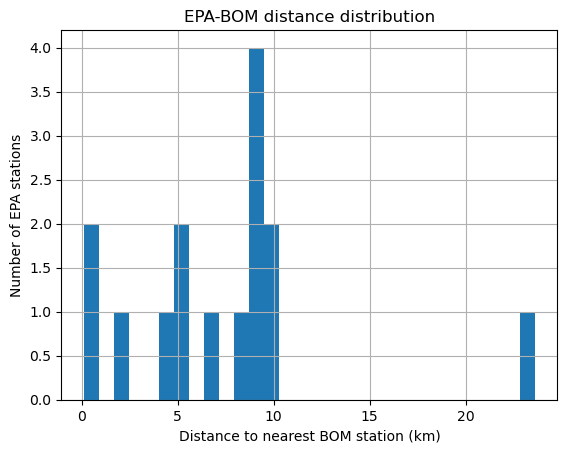

In [15]:
import matplotlib.pyplot as plt
epa_to_bom['distance_km'].hist(bins=30)
plt.xlabel("Distance to nearest BOM station (km)")
plt.ylabel("Number of EPA stations")
plt.title("EPA-BOM distance distribution")
plt.show()

In [16]:
epa_to_bom = pd.read_csv("epa_to_bom.csv")
epa_to_bom = epa_to_bom[epa_to_bom['distance_km'] < 20]  # 排除 melton

In [25]:
import os
import csv
from pathlib import Path
import pandas as pd

# 统一后的 11 列
COLUMN_NAMES = [
    'Station','Date','Evapotranspiration','Rain','Pan_Evaporation',
    'Max_Temperature','Min_Temperature','Max_Rel_Humidity','Min_Rel_Humidity',
    'Avg_10m_Wind_Speed','Solar_Radiation'
]

# 输入/输出目录
BOM_DIR = '/Users/wangshihan/Air Quality Research/BOM SITES USED'
OUT_DIR = '/Users/wangshihan/Air Quality Research/Cleaned_BOM'
Path(OUT_DIR).mkdir(parents=True, exist_ok=True)

def read_bom_csv(path: str) -> pd.DataFrame:
    """固定跳过前 13 行，直接套用统一的列名。"""
    # 强制用 latin1 兼容所有奇怪字符
    df = pd.read_csv(
        path,
        encoding='latin1',
        engine='python',
        sep=',',
        skiprows=13,          # 固定跳过前 13 行
        header=None,          # 不用文件里的表头
        names=COLUMN_NAMES,   # 直接套用统一列名
        usecols=range(11),    # 只要前 11 列
        skip_blank_lines=True,
        quoting=csv.QUOTE_MINIMAL,
        on_bad_lines='skip'
    )
    return df

def is_totals_row(v):
    s = str(v).strip().lower()
    return 'total' in s

def clean_one_file(src_path: str) -> pd.DataFrame:
    df = read_bom_csv(src_path)

    # 删除 Totals 行
    df = df[~df['Station'].apply(is_totals_row)]

    # 转换 Date 列（BOM 是日/月/年）
    ok_date = pd.to_datetime(df['Date'], errors='coerce', dayfirst=True)
    df = df[ok_date.notna()].copy()
    df['Date'] = ok_date

    # 数值列转 float
    num_cols = [c for c in df.columns if c not in ('Station','Date')]
    df[num_cols] = df[num_cols].apply(pd.to_numeric, errors='coerce').round(2)

    return df

# 遍历所有文件
for root, _, files in os.walk(BOM_DIR):
    for name in files:
        if not name.lower().endswith('.csv') or name.endswith('_cleaned.csv'):
            continue
        src = os.path.join(root, name)
        try:
            df = clean_one_file(src)
            rel = os.path.relpath(src, BOM_DIR)
            out_rel = os.path.splitext(rel)[0] + '_cleaned.csv'
            out_path = os.path.join(OUT_DIR, out_rel)
            Path(os.path.dirname(out_path)).mkdir(parents=True, exist_ok=True)
            df.to_csv(out_path, index=False)
            print(f"✅ {rel} -> {os.path.relpath(out_path, OUT_DIR)} (rows={len(df)})")
        except Exception as e:
            print(f"❌ 错误跳过文件: {src}, 原因: {e}")

✅ breakwater_(geelong_racecourse)/breakwater_(geelong_racecourse)-202402.csv -> breakwater_(geelong_racecourse)/breakwater_(geelong_racecourse)-202402_cleaned.csv (rows=29)
✅ breakwater_(geelong_racecourse)/breakwater_(geelong_racecourse)-202403.csv -> breakwater_(geelong_racecourse)/breakwater_(geelong_racecourse)-202403_cleaned.csv (rows=31)
✅ breakwater_(geelong_racecourse)/breakwater_(geelong_racecourse)-202401.csv -> breakwater_(geelong_racecourse)/breakwater_(geelong_racecourse)-202401_cleaned.csv (rows=31)
✅ breakwater_(geelong_racecourse)/breakwater_(geelong_racecourse)-202404.csv -> breakwater_(geelong_racecourse)/breakwater_(geelong_racecourse)-202404_cleaned.csv (rows=30)
✅ breakwater_(geelong_racecourse)/breakwater_(geelong_racecourse)-202410.csv -> breakwater_(geelong_racecourse)/breakwater_(geelong_racecourse)-202410_cleaned.csv (rows=31)
✅ breakwater_(geelong_racecourse)/breakwater_(geelong_racecourse)-202411.csv -> breakwater_(geelong_racecourse)/breakwater_(geelong_rac

In [89]:
import os
import csv
from pathlib import Path
import pandas as pd

# === 统一列名 ===
COLUMN_NAMES = [
    'Station','Date','Evapotranspiration','Rain','Pan_Evaporation',
    'Max_Temperature','Min_Temperature','Max_Rel_Humidity','Min_Rel_Humidity',
    'Avg_10m_Wind_Speed','Solar_Radiation'
]

# === 输入与输出路径 ===
BOM_DIR = '/Users/wangshihan/Air Quality Research/BOM SITES USED'
CLEANED_DIR = '/Users/wangshihan/Air Quality Research/Cleaned_BOM_Merged/temp'
MERGED_DIR = '/Users/wangshihan/Air Quality Research/Cleaned_BOM_Merged'
Path(CLEANED_DIR).mkdir(parents=True, exist_ok=True)
Path(MERGED_DIR).mkdir(parents=True, exist_ok=True)

# === 通用读取函数 ===
def read_bom_csv(path: str) -> pd.DataFrame:
    df = pd.read_csv(
        path,
        encoding='latin1',
        engine='python',
        sep=',',
        skiprows=13,
        header=None,
        names=COLUMN_NAMES,
        usecols=range(11),
        skip_blank_lines=True,
        quoting=csv.QUOTE_MINIMAL,
        on_bad_lines='skip'
    )
    return df

def is_totals_row(v):
    s = str(v).strip().lower()
    return 'total' in s

# === 清洗函数 ===
def clean_one_file(src_path: str) -> pd.DataFrame:
    df = read_bom_csv(src_path)
    df = df[~df['Station'].apply(is_totals_row)]

    # 日期处理
    ok_date = pd.to_datetime(df['Date'], errors='coerce', dayfirst=True)
    df = df[ok_date.notna()].copy()
    df['Date'] = ok_date

    # 数值列转换
    num_cols = [c for c in df.columns if c not in ('Station','Date')]
    df[num_cols] = df[num_cols].apply(pd.to_numeric, errors='coerce').round(2)

    return df

# === 遍历清洗所有文件 ===
station_dfs = {}

for root, _, files in os.walk(BOM_DIR):
    for name in files:
        if not name.lower().endswith('.csv'):
            continue

        src = os.path.join(root, name)
        try:
            df = clean_one_file(src)

            # 提取站点名（文件夹名或文件前缀）
            rel = os.path.relpath(src, BOM_DIR)
            station = rel.split(os.sep)[0]

            # 保存 cleaned 文件（单月）
            out_rel = os.path.splitext(rel)[0] + '_cleaned.csv'
            out_path = os.path.join(CLEANED_DIR, out_rel)
            Path(os.path.dirname(out_path)).mkdir(parents=True, exist_ok=True)
            df.to_csv(out_path, index=False)

            # 累积每个站点
            station_dfs.setdefault(station, []).append(df)
            print(f"✅ {station} cleaned: {len(df)} rows")

        except Exception as e:
            print(f"❌ 错误跳过 {src}: {e}")

# === 合并并排序每个站点的数据 ===
for station, dfs in station_dfs.items():
    try:
        merged_df = pd.concat(dfs, ignore_index=True)
        merged_df = merged_df.drop_duplicates(subset='Date').sort_values('Date')
        merged_path = os.path.join(MERGED_DIR, f"{station}_merged.csv")
        merged_df.to_csv(merged_path, index=False)
        print(f"📦 合并完成: {station} ({len(merged_df)} 条记录) -> {merged_path}")
    except Exception as e:
        print(f"⚠️ 合并 {station} 出错: {e}")

print("\n🎯 所有站点清洗与合并完成！")

✅ laverton_raaf cleaned: 31 rows
✅ laverton_raaf cleaned: 31 rows
✅ laverton_raaf cleaned: 28 rows
✅ laverton_raaf cleaned: 28 rows
✅ laverton_raaf cleaned: 30 rows
✅ laverton_raaf cleaned: 31 rows
✅ laverton_raaf cleaned: 30 rows
✅ laverton_raaf cleaned: 31 rows
✅ laverton_raaf cleaned: 31 rows
✅ laverton_raaf cleaned: 30 rows
✅ laverton_raaf cleaned: 31 rows
✅ laverton_raaf cleaned: 30 rows
✅ laverton_raaf cleaned: 31 rows
✅ laverton_raaf cleaned: 30 rows
✅ laverton_raaf cleaned: 31 rows
✅ laverton_raaf cleaned: 30 rows
✅ laverton_raaf cleaned: 31 rows
✅ laverton_raaf cleaned: 30 rows
✅ laverton_raaf cleaned: 31 rows
✅ laverton_raaf cleaned: 31 rows
✅ laverton_raaf cleaned: 30 rows
✅ laverton_raaf cleaned: 31 rows
✅ laverton_raaf cleaned: 31 rows
✅ laverton_raaf cleaned: 31 rows
✅ laverton_raaf cleaned: 31 rows
✅ laverton_raaf cleaned: 30 rows
✅ laverton_raaf cleaned: 31 rows
✅ laverton_raaf cleaned: 30 rows
✅ laverton_raaf cleaned: 31 rows
✅ laverton_raaf cleaned: 28 rows
✅ laverton

In [26]:
exclude_sheets = {"Data Info Panel", "Metadata", "AllData"}
epa_daily_all = []
for sheet in xls.sheet_names:
    if sheet not in exclude_sheets:
        df_single_epa = pd.read_excel(xls, sheet_name=sheet)
        df_single_epa['datetime_local'] = pd.to_datetime(df_single_epa['datetime_local'])
        df_single_epa['date'] = df_single_epa['datetime_local'].dt.date
        epa_daily=df_single_epa.groupby('date').mean(numeric_only=True).reset_index()

        location_id = df_single_epa['location_id'].iloc[0]
        epa_daily['location_id'] = location_id

        epa_daily_all.append(epa_daily)
        print(f"✅ 已处理: {sheet}")
    
# 合并所有站点的 daily 数据
epa_daily_all_df = pd.concat(epa_daily_all, ignore_index=True)

# 示例保存合并结果（可选）
epa_daily_all_df.to_csv('epa_daily_all.csv', index=False)

✅ 已处理: Morwell East_10017
✅ 已处理: Mooroolbark_10136
✅ 已处理: Altona North_10006
✅ 已处理: Dandenong_10022
✅ 已处理: Point Cook_10005
✅ 已处理: Geelong South_10107
✅ 已处理: Traralgon_10011
✅ 已处理: Alphington_10001
✅ 已处理: Melton_10169
✅ 已处理: Melbourne CBD_10239
✅ 已处理: Box Hill_10042
✅ 已处理: Brighton_10007
✅ 已处理: Morwell South_10217
✅ 已处理: Macleod_10377
✅ 已处理: Brooklyn_1112


In [64]:
import os
import pandas as pd
from pathlib import Path

exclude_sheets = {"Data Info Panel", "Metadata", "AllData"}
clients_root = "/Users/wangshihan/Air Quality Research/2024_EPA_DAILY"  # 你想放的目录
Path(clients_root).mkdir(parents=True, exist_ok=True)

manifest = []  # 保存站点清单，方便后续FL加载

for sheet in xls.sheet_names:
    if sheet in exclude_sheets:
        continue

    df_single_epa = pd.read_excel(xls, sheet_name=sheet)

    # 统一日期到“日”粒度
    df_single_epa['datetime_local'] = pd.to_datetime(df_single_epa['datetime_local'])
    df_single_epa['date'] = df_single_epa['datetime_local'].dt.date

    # 求日均
    epa_daily = df_single_epa.groupby('date').mean(numeric_only=True).reset_index()

    # 标注站点
    location_id = int(df_single_epa['location_id'].iloc[0])
    epa_daily['location_id'] = location_id

    # 保存到：clients_epa_daily/{location_id}/epa_daily_{location_id}.csv
    out_dir = Path(clients_root) / f"{location_id}"
    out_dir.mkdir(parents=True, exist_ok=True)
    out_path = out_dir / f"epa_daily_{location_id}.csv"
    epa_daily.to_csv(out_path, index=False)

    # 记录到 manifest
    manifest.append({
        "location_id": location_id,
        "station_name": str(sheet),
        "path": str(out_path)
    })

    print(f"✅ 已处理并保存: {sheet} -> {out_path}")

# 可选：写一个总清单，训练时读取它来初始化各 client
pd.DataFrame(manifest).to_csv(Path(clients_root) / "clients_manifest.csv", index=False)
print(f"📄 Manifest 写入: {Path(clients_root) / 'clients_manifest.csv'}")

✅ 已处理并保存: Morwell East_10017 -> /Users/wangshihan/Air Quality Research/2024_EPA_DAILY/10017/epa_daily_10017.csv
✅ 已处理并保存: Mooroolbark_10136 -> /Users/wangshihan/Air Quality Research/2024_EPA_DAILY/10136/epa_daily_10136.csv
✅ 已处理并保存: Altona North_10006 -> /Users/wangshihan/Air Quality Research/2024_EPA_DAILY/10006/epa_daily_10006.csv
✅ 已处理并保存: Dandenong_10022 -> /Users/wangshihan/Air Quality Research/2024_EPA_DAILY/10022/epa_daily_10022.csv
✅ 已处理并保存: Point Cook_10005 -> /Users/wangshihan/Air Quality Research/2024_EPA_DAILY/10005/epa_daily_10005.csv
✅ 已处理并保存: Geelong South_10107 -> /Users/wangshihan/Air Quality Research/2024_EPA_DAILY/10107/epa_daily_10107.csv
✅ 已处理并保存: Traralgon_10011 -> /Users/wangshihan/Air Quality Research/2024_EPA_DAILY/10011/epa_daily_10011.csv
✅ 已处理并保存: Alphington_10001 -> /Users/wangshihan/Air Quality Research/2024_EPA_DAILY/10001/epa_daily_10001.csv
✅ 已处理并保存: Melton_10169 -> /Users/wangshihan/Air Quality Research/2024_EPA_DAILY/10169/epa_daily_10169.csv
✅ 已处理并保存

In [76]:
from pathlib import Path
import pandas as pd
import os
import re  # ✅ 用来清理非法字符

# ===== 参数设置 =====
start_year = 2021
end_year = 2024
base_dir = Path("/Users/wangshihan/Air Quality Research")

# 不需要处理的 sheet
exclude_sheets = {"Data Info Panel", "Metadata", "AllData"}

# ===== 主循环 =====
for year in range(start_year, end_year + 1):
    file_path = base_dir / f"{year}_AIR_QUALITY.xlsx"
    if not file_path.exists():
        print(f"⚠️ 跳过 {year}：未找到文件 {file_path.name}")
        continue

    print(f"\n📘 正在处理 {file_path.name} ...")
    try:
        # 打开 Excel 文件
        xls = pd.ExcelFile(file_path)

        # 输出目录：例如 /Users/.../2023_EPA_DAILY/
        clients_root = base_dir / f"{year}_EPA_DAILY"
        Path(clients_root).mkdir(parents=True, exist_ok=True)

        manifest = []  # 保存站点清单

        # 遍历每个站点 sheet
        for sheet in xls.sheet_names:
            if sheet in exclude_sheets:
                continue

            df_single_epa = pd.read_excel(xls, sheet_name=sheet)

            # 有些 sheet 可能是空的
            if df_single_epa.empty:
                print(f"⚠️ 跳过空 sheet: {sheet}")
                continue

            # 检查是否有 datetime_local 和 location_id
            if "datetime_local" not in df_single_epa.columns or "location_id" not in df_single_epa.columns:
                print(f"⚠️ 跳过 {sheet}：缺少 datetime_local 或 location_id 列")
                continue

            # ===== 数据清理与聚合 =====
            df_single_epa['datetime_local'] = pd.to_datetime(df_single_epa['datetime_local'], errors='coerce')
            df_single_epa = df_single_epa.dropna(subset=['datetime_local'])
            df_single_epa['date'] = df_single_epa['datetime_local'].dt.date

            # 求每日均值
            epa_daily = df_single_epa.groupby('date').mean(numeric_only=True).reset_index()

            # 记录站点
            location_id = int(df_single_epa['location_id'].iloc[0])

            # ✅ 获取站点名
            if 'location_name' in df_single_epa.columns:
                location_name = str(df_single_epa['location_name'].iloc[0])
            else:
                location_name = str(sheet)

            # ✅ 清理站点名中的非法字符
            safe_name = re.sub(r'[^A-Za-z0-9_-]', '_', location_name.strip())

            epa_daily['location_id'] = location_id
            epa_daily['location_name'] = location_name

            # ===== 保存结果 =====
            # ⚠️ 改动点：不再创建子文件夹，直接保存在根目录下
            out_path = clients_root / f"{safe_name}_{location_id}.csv"
            epa_daily.to_csv(out_path, index=False)

            manifest.append({
                "location_id": location_id,
                "location_name": location_name,
                "station_name": str(sheet),
                "path": str(out_path)
            })

            print(f"✅ 已处理并保存: {sheet} -> {out_path.name}")

        # 保存清单
        manifest_path = clients_root / "clients_manifest.csv"
        pd.DataFrame(manifest).to_csv(manifest_path, index=False)
        print(f"📄 Manifest 写入: {manifest_path}")

    except Exception as e:
        print(f"❌ 处理 {file_path.name} 时出错: {e}")


📘 正在处理 2021_AIR_QUALITY.xlsx ...
✅ 已处理并保存: Morwell East_10017 -> Morwell_East_10017.csv
✅ 已处理并保存: Mooroolbark_10136 -> Mooroolbark_10136.csv
✅ 已处理并保存: Morwell South_10217 -> Morwell_South_10217.csv
✅ 已处理并保存: Altona North_10006 -> Altona_North_10006.csv
✅ 已处理并保存: Dandenong_10022 -> Dandenong_10022.csv
✅ 已处理并保存: Point Cook_10005 -> Point_Cook_10005.csv
✅ 已处理并保存: Brooklyn_10213 -> Brooklyn_10213.csv
✅ 已处理并保存: Geelong South_10107 -> Geelong_South_10107.csv
✅ 已处理并保存: Traralgon_10011 -> Traralgon_10011.csv
✅ 已处理并保存: Alphington_10001 -> Alphington_10001.csv
✅ 已处理并保存: Footscray_10003 -> Footscray_10003.csv
✅ 已处理并保存: Melton_10169 -> Melton_10169.csv
✅ 已处理并保存: Churchill_10219 -> Churchill_10219.csv
✅ 已处理并保存: Campbellfield_10425 -> Campbellfield_10425.csv
✅ 已处理并保存: Melbourne CBD_10239 -> Melbourne_CBD_10239.csv
✅ 已处理并保存: Newborough_10352 -> Newborough_10352.csv
✅ 已处理并保存: Moe_10218 -> Moe_10218.csv
✅ 已处理并保存: Bendigo_10432 -> Bendigo_10432.csv
✅ 已处理并保存: Footscray_10451 -> Footscray_10451.csv
✅ 已处理

In [77]:
import shutil
backup_dir = base_dir / "EPA_Backup"
shutil.copytree(base_dir, backup_dir, dirs_exist_ok=True)
print("📦 已备份原始数据到 EPA_Backup/")

📦 已备份原始数据到 EPA_Backup/


In [82]:
from pathlib import Path
import pandas as pd
import numpy as np
import os

# ===== 参数 =====
base_dir = Path("/Users/wangshihan/Air Quality Research")
start_year = 2021
end_year = 2024

# 允许的目标列（优先级从高到低）
target_cols = ["SBPM25", "BPM2.5", "PM25", "PM2.5", "PM10"]

# ===== 主循环 =====
for year in range(start_year, end_year + 1):
    year_dir = base_dir / f"{year}_EPA_DAILY"
    if not year_dir.exists():
        print(f"⚠️ 跳过 {year}：未找到文件夹 {year_dir}")
        continue

    print(f"\n📘 正在清理 {year} 年的文件夹：{year_dir}")

    for csv_file in year_dir.glob("*.csv"):
        if csv_file.name == "clients_manifest.csv":
            continue

        try:
            df = pd.read_csv(
                csv_file,
                na_values=["", " ", "NA", "NaN", "nan", "--", "..."],
                keep_default_na=True
            )
            df.columns = [c.strip().upper() for c in df.columns]
            df = df.replace(r'^\s*$', np.nan, regex=True)

            # 检查是否存在 PM 列
            existing_targets = [col for col in target_cols if col in df.columns]

            # 🚫 如果完全没有 PM 列 → 删除整个文件
            if not existing_targets:
                print(f"🗑️ {csv_file.name} 没有任何 PM 列，已删除整个文件。")
                os.remove(csv_file)
                continue

            # 删除所有 PM 列都为空的行
            before = len(df)
            df = df.dropna(subset=existing_targets, how="all")
            after = len(df)

            removed = before - after
            percent = (removed / before * 100) if before > 0 else 0
            print(f"✅ {csv_file.name}: 删除 {removed} 行（{percent:.1f}%）无 PM 数据行")

            # 如果删除后整个文件没剩下数据，也删掉
            if after == 0:
                os.remove(csv_file)
                print(f"🗑️ {csv_file.name}: 全部行都无 PM 数据，文件已删除。")
                continue

            # 保存
            df.to_csv(csv_file, index=False)

        except Exception as e:
            print(f"❌ 清理 {csv_file.name} 时出错: {e}")

print("\n🎯 全部年份的 EPA 文件已清理完成！")


📘 正在清理 2021 年的文件夹：/Users/wangshihan/Air Quality Research/2021_EPA_DAILY
✅ Morwell_East_10017.csv: 删除 0 行（0.0%）无 PM 数据行
✅ Traralgon_10011.csv: 删除 0 行（0.0%）无 PM 数据行
✅ Footscray_10451.csv: 删除 0 行（0.0%）无 PM 数据行
✅ Melton_10169.csv: 删除 0 行（0.0%）无 PM 数据行
✅ Mooroolbark_10136.csv: 删除 0 行（0.0%）无 PM 数据行
✅ Brooklyn_10213.csv: 删除 0 行（0.0%）无 PM 数据行
✅ Melbourne_CBD_10239.csv: 删除 0 行（0.0%）无 PM 数据行
✅ Newborough_10352.csv: 删除 0 行（0.0%）无 PM 数据行
✅ Dandenong_10022.csv: 删除 0 行（0.0%）无 PM 数据行
✅ Bendigo_10432.csv: 删除 0 行（0.0%）无 PM 数据行
✅ Campbellfield_10425.csv: 删除 0 行（0.0%）无 PM 数据行
🗑️ Point_Cook_10005.csv 没有任何 PM 列，已删除整个文件。
✅ Churchill_10219.csv: 删除 0 行（0.0%）无 PM 数据行
✅ Footscray_10003.csv: 删除 0 行（0.0%）无 PM 数据行
🗑️ Altona_North_10006.csv 没有任何 PM 列，已删除整个文件。
✅ Geelong_South_10107.csv: 删除 0 行（0.0%）无 PM 数据行
✅ Alphington_10001.csv: 删除 0 行（0.0%）无 PM 数据行
✅ Brighton_10007.csv: 删除 0 行（0.0%）无 PM 数据行
✅ Morwell_South_10217.csv: 删除 0 行（0.0%）无 PM 数据行
✅ Moe_10218.csv: 删除 0 行（0.0%）无 PM 数据行
✅ Box_Hill_10042.csv: 删除 0 行（0.0%）无 P

In [83]:
from pathlib import Path
import pandas as pd

# ===== 参数设置 =====
base_dir = Path("/Users/wangshihan/Air Quality Research")
output_dir = base_dir / "Merged_EPA"
output_dir.mkdir(exist_ok=True)

# 所有年份文件夹（自动找）
epa_year_dirs = sorted(base_dir.glob("*_EPA_DAILY"))

# 记录所有文件路径
station_files = {}

# ===== 收集每个站点的所有 CSV =====
for year_dir in epa_year_dirs:
    if not year_dir.is_dir():
        continue
    for csv_file in year_dir.glob("*.csv"):
        if csv_file.name == "clients_manifest.csv":
            continue
        station_name = csv_file.name  # 比如 Box_Hill_10042.csv
        station_files.setdefault(station_name, []).append(csv_file)

# ===== 合并每个站点 =====
for station_name, paths in station_files.items():
    dfs = []
    for path in sorted(paths):  # 按年份顺序拼接
        try:
            df = pd.read_csv(path)
            df['Source_Year'] = path.parent.name[:4]  # 加一列标记来源年份
            dfs.append(df)
        except Exception as e:
            print(f"⚠️ 读取 {path.name} 时出错: {e}")
    
    if not dfs:
        continue

    # 纵向合并
    merged = pd.concat(dfs, ignore_index=True)

    # 去除重复日期（如果有）
    if 'date' in merged.columns:
        merged = merged.sort_values('date').drop_duplicates(subset='date', keep='last')

    # 输出保存
    out_path = output_dir / station_name
    merged.to_csv(out_path, index=False)
    print(f"✅ 合并完成: {station_name} -> {out_path}")

print("\n🎯 所有站点合并完成！结果已保存到 'Merged_EPA' 文件夹。")

✅ 合并完成: Morwell_East_10017.csv -> /Users/wangshihan/Air Quality Research/Merged_EPA/Morwell_East_10017.csv
✅ 合并完成: Traralgon_10011.csv -> /Users/wangshihan/Air Quality Research/Merged_EPA/Traralgon_10011.csv
✅ 合并完成: Footscray_10451.csv -> /Users/wangshihan/Air Quality Research/Merged_EPA/Footscray_10451.csv
✅ 合并完成: Melton_10169.csv -> /Users/wangshihan/Air Quality Research/Merged_EPA/Melton_10169.csv
✅ 合并完成: Mooroolbark_10136.csv -> /Users/wangshihan/Air Quality Research/Merged_EPA/Mooroolbark_10136.csv
✅ 合并完成: Brooklyn_10213.csv -> /Users/wangshihan/Air Quality Research/Merged_EPA/Brooklyn_10213.csv
✅ 合并完成: Melbourne_CBD_10239.csv -> /Users/wangshihan/Air Quality Research/Merged_EPA/Melbourne_CBD_10239.csv
✅ 合并完成: Newborough_10352.csv -> /Users/wangshihan/Air Quality Research/Merged_EPA/Newborough_10352.csv
✅ 合并完成: Dandenong_10022.csv -> /Users/wangshihan/Air Quality Research/Merged_EPA/Dandenong_10022.csv
✅ 合并完成: Bendigo_10432.csv -> /Users/wangshihan/Air Quality Research/Merged_EPA/

In [107]:
from pathlib import Path
import pandas as pd

# ===== 参数 =====
merged_dir = Path("/Users/wangshihan/Air Quality Research/Finalized_Dataset")
output_path = merged_dir / "merged_summary.csv"

summary = []

# ===== 遍历所有 CSV 文件 =====
for csv_file in merged_dir.glob("*.csv"):
    try:
        df = pd.read_csv(csv_file)
        n_rows = len(df)

        # 尝试从文件名提取 name 和 id
        name_part = csv_file.stem  # 例如 "Box_Hill_10042"
        if "_" in name_part:
            parts = name_part.rsplit("_", 1)
            location_name = parts[0].replace("_", " ")
            location_id = parts[1]
        else:
            location_name = name_part
            location_id = "Unknown"

        summary.append({
            "location_name": location_name,
            "location_id": location_id,
            "rows": n_rows
        })
        print(f"✅ {csv_file.name}: {n_rows} 行")

    except Exception as e:
        print(f"❌ 读取 {csv_file.name} 时出错: {e}")

# ===== 输出汇总表 =====
summary_df = pd.DataFrame(summary)
summary_df = summary_df.sort_values("rows", ascending=False)
summary_df.to_csv(output_path, index=False)

print(f"\n📄 汇总完成！结果已保存到：{output_path}")

✅ Melton_10169_merged.csv: 1248 行
✅ Morwell_East_10017_merged.csv: 400 行
✅ Brighton_10007_merged.csv: 1220 行
✅ Morwell_South_10217_merged.csv: 715 行
✅ Box_Hill_10042_merged.csv: 1134 行
✅ Alphington_10001_merged.csv: 1292 行
✅ Dandenong_10022_merged.csv: 719 行
✅ Macleod_10377_merged.csv: 220 行
✅ Melbourne_CBD_10239_merged.csv: 1399 行
✅ Traralgon_10011_merged.csv: 1351 行
✅ Geelong_South_10107_merged.csv: 1210 行

📄 汇总完成！结果已保存到：/Users/wangshihan/Air Quality Research/Finalized_Dataset/merged_summary.csv


In [87]:
import pandas as pd
from pathlib import Path

file_path = Path("/Users/wangshihan/Air Quality Research/2024_AIR_QUALITY.xlsx")

# 读取 AllData
df_all = pd.read_excel(file_path, sheet_name='AllData')
df_all.columns = df_all.columns.str.strip()  # 清理列名前后空格

# 只保留关心的列
cols_to_show = ['location_name', 'location_id', 'latitude', 'longitude']

# 检查是否存在这些列（有的文件可能列名略不同）
available_cols = [col for col in cols_to_show if col in df_all.columns]

# 打印结果
print(df_all[available_cols].drop_duplicates())
print(available_cols)

       location_name  location_id   latitude   longitude
0       Morwell East        10017 -38.229393  146.424454
1        Mooroolbark        10136 -37.774967  145.328500
2       Altona North        10006 -37.844550  144.862900
3          Dandenong        10022 -37.985760  145.198700
4         Point Cook        10005 -37.926315  144.756700
5      Geelong South        10107 -38.173560  144.370300
8          Traralgon        10011 -38.194282  146.531464
15        Alphington        10001 -37.778408  145.030600
48            Melton        10169 -37.706455  144.566900
90     Melbourne CBD        10239 -37.807396  144.970000
103         Box Hill        10042 -37.828728  145.132400
119         Brighton        10007 -37.913547  144.998000
1026   Morwell South        10217 -38.239292  146.387300
8730         Macleod        10377 -37.722477  145.057600
47641       Brooklyn         1112 -37.822098  144.847100
['location_name', 'location_id', 'latitude', 'longitude']


In [106]:
import pandas as pd
import numpy as np
from pathlib import Path

# ==== 路径设置 ====
base = Path("/Users/wangshihan/Air Quality Research")
src_dir = base / "EPA_BOM_Merged"
out_dir = base / "Finalized_Dataset"
out_dir.mkdir(exist_ok=True)

def norm(name: str) -> str:
    """列名规范化：去空格、转小写、去点和下划线"""
    return name.strip().lower().replace(".", "").replace("_", "")

# ==== 遍历所有文件 ====
for f in src_dir.glob("*.csv"):
    try:
        # ① 读取
        df = pd.read_csv(f)

        # ② 标准化列名（统一小写+去空格）
        new_cols = [c.strip().lower() for c in df.columns]
        df.columns = new_cols

        # ③ 删除重复列：这里必须手动同步索引，避免 Unalignable boolean 错误
        dup_mask = pd.Index([norm(c) for c in df.columns]).duplicated(keep="first")
        df = df.loc[:, ~dup_mask]

        # ④ 找出所有 PM2.5 相关列
        pm25_candidates = [c for c in df.columns if "pm25" in norm(c) or "bpm25" in norm(c) or "sbpm25" in norm(c)]

        if not pm25_candidates:
            print(f"⚠️ 跳过（无 PM2.5 列）: {f.name}")
            continue

        # ⑤ 合并多个 PM2.5 列为一个
        df["pm25"] = np.nan
        for col in pm25_candidates:
            df["pm25"] = df["pm25"].combine_first(pd.to_numeric(df[col], errors="coerce"))

        # ⑥ 删除旧 PM2.5 列（只保留新的 pm25）
        df.drop(columns=[c for c in pm25_candidates if c != "pm25"], inplace=True, errors="ignore")
        
        # 删除 pm25 为空的行
        df = df[df["pm25"].notna()].reset_index(drop=True)

        # ⑦ 统一日期列名并排序
        date_cols = [c for c in df.columns if "date" in c]
        if date_cols:
            df.rename(columns={date_cols[0]: "Date"}, inplace=True)
        else:
            raise ValueError("未找到日期列")

        df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
        df = df.sort_values("Date").reset_index(drop=True)

        # ⑧ 保存
        out_path = out_dir / f.name
        df.to_csv(out_path, index=False)
        print(f"✅ 已修正并保存: {f.name} | 合并列: {pm25_candidates}")

    except Exception as e:
        print(f"❌ 处理失败 {f.name}: {e}")

print("\n🎯 所有文件修正完成！")

✅ 已修正并保存: Melton_10169_merged.csv | 合并列: ['sbpm25']
✅ 已修正并保存: Morwell_East_10017_merged.csv | 合并列: ['bpm2.5']
✅ 已修正并保存: Brighton_10007_merged.csv | 合并列: ['sbpm25']
⚠️ 跳过（无 PM2.5 列）: Brooklyn_1112_merged.csv
⚠️ 跳过（无 PM2.5 列）: Mooroolbark_10136_merged.csv
✅ 已修正并保存: Morwell_South_10217_merged.csv | 合并列: ['bpm2.5']
✅ 已修正并保存: Box_Hill_10042_merged.csv | 合并列: ['sbpm25']
✅ 已修正并保存: Alphington_10001_merged.csv | 合并列: ['bpm2.5', 'sbpm25']
✅ 已修正并保存: Dandenong_10022_merged.csv | 合并列: ['sbpm25']
✅ 已修正并保存: Macleod_10377_merged.csv | 合并列: ['sbpm25']
✅ 已修正并保存: Melbourne_CBD_10239_merged.csv | 合并列: ['bpm2.5', 'sbpm25']
✅ 已修正并保存: Traralgon_10011_merged.csv | 合并列: ['bpm2.5', 'sbpm25']
✅ 已修正并保存: Geelong_South_10107_merged.csv | 合并列: ['bpm2.5', 'sbpm25']

🎯 所有文件修正完成！
